We will analyze the MLP (2 layers, 2 neurons each) on a toy circle dataset

In [1]:
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from mlp import MLP

In [2]:
np.random.seed(42)

In [11]:
def one_hot(labels, num_classes):
    encoded = np.zeros((labels.shape[0], num_classes))
    encoded[np.arange(labels.shape[0]), labels] = 1
    return encoded

In [15]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    preds = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, preds, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.tight_layout()

In [12]:
X, y = make_circles(n_samples=500, noise=0.15, factor=0.5, random_state=42)
y_one_hot = one_hot(y, num_classes=2)
print(X.shape)
print(y_one_hot.shape)

(500, 2)
(500, 2)


In [13]:
X_train, X_test, y_train, y_test, y_train_labels, y_test_labels = train_test_split(
        X, y_one_hot, y, test_size=0.2, random_state=42, stratify=y
    )
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 2)
(100, 2)
(400, 2)
(100, 2)


In [14]:
model = MLP(input_size=2, hidden_size=16, output_size=2)
model.train(X_train, y_train, epochs=2000, learning_rate=0.01)

Epoch 100, Loss: 0.2116
Epoch 200, Loss: 0.1571
Epoch 300, Loss: 0.1453
Epoch 400, Loss: 0.1408
Epoch 500, Loss: 0.1383
Epoch 600, Loss: 0.1364
Epoch 700, Loss: 0.1349
Epoch 800, Loss: 0.1337
Epoch 900, Loss: 0.1326
Epoch 1000, Loss: 0.1317
Epoch 1100, Loss: 0.1309
Epoch 1200, Loss: 0.1303
Epoch 1300, Loss: 0.1297
Epoch 1400, Loss: 0.1292
Epoch 1500, Loss: 0.1287
Epoch 1600, Loss: 0.1283
Epoch 1700, Loss: 0.1279
Epoch 1800, Loss: 0.1275
Epoch 1900, Loss: 0.1272
Epoch 2000, Loss: 0.1269


In [16]:
train_acc = np.mean(model.predict(X_train) == y_train_labels)
test_acc = np.mean(model.predict(X_test) == y_test_labels)
print(f"Train accuracy: {train_acc:.2%}")
print(f"Test accuracy:  {test_acc:.2%}")

Train accuracy: 95.50%
Test accuracy:  92.00%


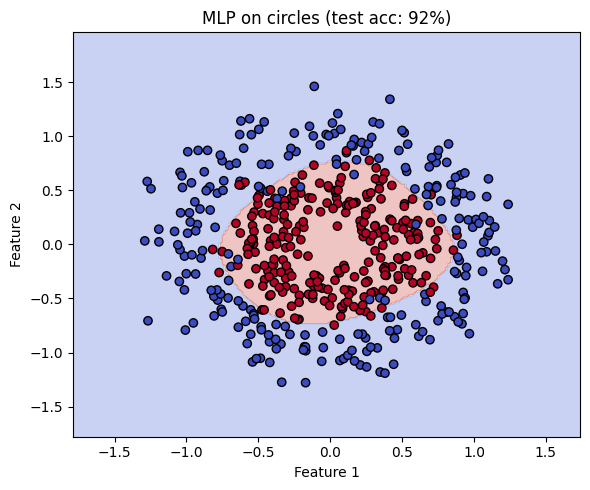

In [17]:
plot_decision_boundary(model, X, y, f"MLP on circles (test acc: {test_acc:.0%})")
plt.show()

Test accuracy is 92% suggesting that the MLP is capable to distinguish between the classes.